# Analysis of factors influencing airline passenger satisfaction

The aim of this project is to build a predictive model that will be used for identifying the most important factors influencing the level of airline passenger satisfaction, based on their demographic characteristics and experience with the journey. The data used in the project comes from a publicly available dataset made available on the Kaggle platform: https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction.

The scope of work includes the complete process of data exploration, preparation for analysis and construction and evaluation of classification models.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import uniform, randint
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression as LR
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier as RFC, GradientBoostingClassifier as GBC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

pd.options.mode.chained_assignment = None

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Data import

In [3]:
train = pd.read_csv("C:/Users/Laura/Downloads/archive (2)/train.csv")
test = pd.read_csv("C:/Users/Laura/Downloads/archive (2)/test.csv")

In [4]:
data = pd.concat([train, test], axis=0).reset_index(drop=True)

# Data cleaning and preprocessing

In [5]:
print(data.shape)
data.head()

(129880, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [6]:
data = data.drop(columns=['Unnamed: 0', 'id'], errors='ignore')
data.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,39.427957,1190.316392,2.728696,3.057599,2.756876,2.976925,3.204774,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.642193,3.286326,14.713713,15.091129
std,15.119360,997.452477,1.329340,1.526741,1.401740,1.278520,1.329933,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.176669,1.313682,38.071126,38.465650
min,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,844.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [7]:
#Checking for missing values
data.isna().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

In [8]:
# Data imputation for missing values for variable "Arrival Delay in Minutes"
data['Arrival Delay in Minutes'] = data['Arrival Delay in Minutes'].fillna(data['Departure Delay in Minutes'])

In [9]:
# Changing "satisfaction" to a binary variable
le_satisfaction = LabelEncoder()
data['Satisfaction'] = le_satisfaction.fit_transform(data['satisfaction'])
print("\nTarget variable 'Satisfaction' encoded.")
print("Mapping:", dict(zip(le_satisfaction.classes_, le_satisfaction.transform(le_satisfaction.classes_))))
print("Value counts:\n", data['Satisfaction'].value_counts())


Target variable 'Satisfaction' encoded.
Mapping: {'neutral or dissatisfied': np.int64(0), 'satisfied': np.int64(1)}
Value counts:
 Satisfaction
0    73452
1    56428
Name: count, dtype: int64


In [10]:
#Removing outliers
numeric_dataset = data.select_dtypes(np.number)
stats.zscore(numeric_dataset)
data = data[(np.abs(stats.zscore(numeric_dataset)) < 9).all(axis=1)]
data.shape

(129703, 24)

# Exploratory Data Analysis (EDA)

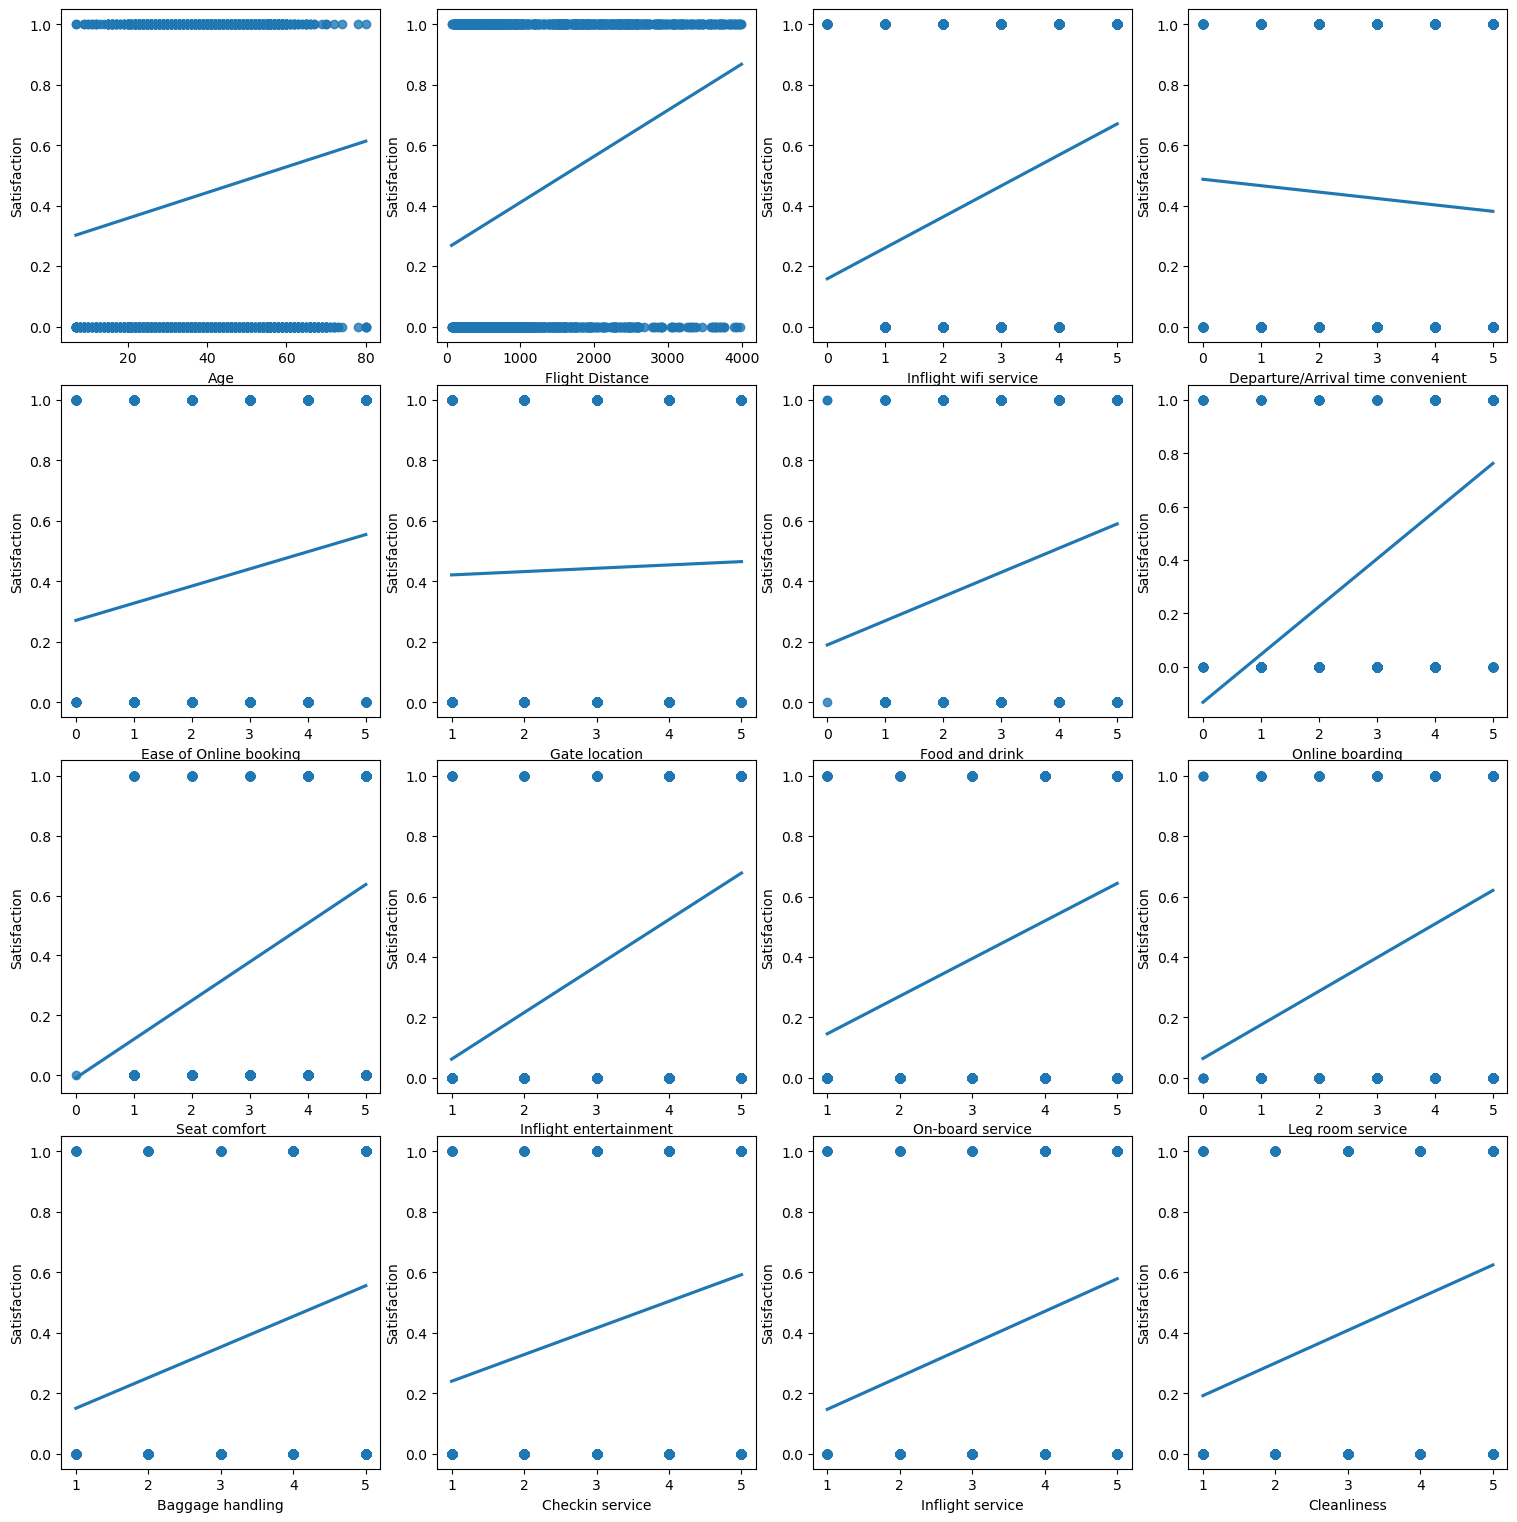

In [11]:
numeric_dataset = data.select_dtypes(np.number)
f, axes = plt.subplots(4, 4, figsize=[15, 15])
plt.tight_layout(pad=0.4, w_pad=1.0, h_pad=1.0)
for n, col in enumerate(numeric_dataset.columns[:16]):
    sns.regplot(x=col, y="Satisfaction", data=data.sample(2000), ax=axes[n // 4, n % 4], ci=None)

# Segmentation

In [12]:
segment_vars = ['Type of Travel', 'Class', 'Customer Type', 'Age', 'Flight Distance']
x_segment = pd.get_dummies(data[segment_vars], drop_first=True)

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_segment)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
data['Segment_ID'] = kmeans.fit_predict(x_scaled)

print(data['Segment_ID'].value_counts())

summary = data.groupby('Segment_ID').agg({
    'Type of Travel': lambda x: x.mode()[0],
    'Class': lambda x: x.mode()[0],
    'Age': 'mean',
    'Flight Distance': 'mean',
    'Satisfaction': 'mean'                   
})

print(summary)

Segment_ID
0    55431
2    50587
1    23685
Name: count, dtype: int64
             Type of Travel     Class        Age  Flight Distance  \
Segment_ID                                                          
0           Business travel  Business  43.173333      1810.868016   
1           Business travel       Eco  30.273422       712.611991   
2           Personal Travel       Eco  39.619092       733.678712   

            Satisfaction  
Segment_ID                
0               0.745088  
1               0.239730  
2               0.185463  


The K-Means clustering analysis  revealed three distinct passenger profiles based on their demographic and travel characteristics. The segments differ significantly in terms of flight distance, class, and overall satisfaction levels.


Segment 0: "The Loyal Business Travelers"

Characteristics: This group consists primarily of long-haul passengers traveling for business purposes in Business Class. They are generally older and show high brand loyalty.

Satisfaction Level: Highest across all groups.

Business Insight: These are the most profitable customers. The airline should focus on premium services (lounges, fast-track) to maintain their high satisfaction.


Segment 1: "Young Business Commuters"

Characteristics: Younger passengers traveling for business reasons, mostly in Economy on shorter distances.

Satisfaction Level: Low.

Business Insight: This segment represents a significant challenge. Despite traveling for work, the lack of business-class amenities and the constraints of economy travel lead to high levels of dissatisfaction among younger professionals.


Segment 2: "Budget  Travelers"

Characteristics: Passengers traveling for personal reasons in Economy Class.

Satisfaction Level: The least satisfied group.

Business Insight:  This is a large segment of price-sensitive travelers. The extremely low satisfaction suggest that the economy experience on personal trips (leisure) is failing to meet basic passenger expectations.

# Logistic Regression


In [13]:
# One-hot encoding
features = [
    'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 
    'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes'
]

X = data[features]
y = data['Satisfaction']

X = pd.get_dummies(X, drop_first=True)
X

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class_Eco,Class_Eco Plus
0,13,460,25,18.0,True,False,True,False,True
1,25,235,1,6.0,True,True,False,False,False
2,26,1142,0,0.0,False,False,False,False,False
3,25,562,11,9.0,False,False,False,False,False
4,61,214,0,0.0,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...
129875,34,526,0,0.0,True,True,False,False,False
129876,23,646,0,0.0,True,False,False,False,False
129877,17,828,0,0.0,False,False,True,True,False
129878,14,1127,0,0.0,True,False,False,False,False


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr_model = LR(max_iter=1000)
lr_model.fit(X_train, y_train)

# Predicted probabilities
y_pred_proba = lr_model.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
print( f"AUC for logistic regression with no regularization: {auc_score:.3f}")

AUC for logistic regression with no regularization: 0.845


In [15]:
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

grid_lr = GridSearchCV(LR(max_iter=1000), param_grid, cv=5, scoring='roc_auc')

grid_lr.fit(X_train, y_train)

print(f"Best parameters: {grid_lr.best_params_}")
best_lr_model = grid_lr.best_estimator_

y_pred_best = best_lr_model.predict_proba(X_test)[:, 1]
final_auc = roc_auc_score(y_test, y_pred_best)
print(f"Final Tuned AUC: {final_auc:.3f}")

Best parameters: {'C': 100}
Final Tuned AUC: 0.845


In [16]:
# Train set AUC
y_train_proba = best_lr_model.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, y_train_proba)

# Test set AUC
y_test_proba = best_lr_model.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, y_test_proba)

print(f"AUC Train: {auc_train:.4f}")
print(f"AUC Test:  {auc_test:.4f}")

AUC Train: 0.8433
AUC Test:  0.8452


# Random Forest Regressor

In [17]:
# By tuning chosen parameters, the model can better adapt to large-scale datasets while maintaining stability.

grid = {
    "n_estimators": [100, 200],
    "max_features": [5, 10],
    "max_depth": [10, 20],
    "min_samples_leaf": [2, 5]
}

In [18]:
print(grid)

{'n_estimators': [100, 200], 'max_features': [5, 10], 'max_depth': [10, 20], 'min_samples_leaf': [2, 5]}


In [19]:
# GridSearchCV — identifies the best-performing hyperparameter combination via exhaustive search and cross-validated ROC-AUC scoring.

tuning_res_rf = GridSearchCV(
    RFC(
        random_state=42,
        class_weight='balanced'
    ),
    param_grid=grid,
    scoring="roc_auc",
    n_jobs=1,     
    cv=3,
    verbose=2
)

tuning_res_rf.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END max_depth=10, max_features=5, min_samples_leaf=2, n_estimators=100; total time=   4.8s
[CV] END max_depth=10, max_features=5, min_samples_leaf=2, n_estimators=100; total time=   4.6s
[CV] END max_depth=10, max_features=5, min_samples_leaf=2, n_estimators=100; total time=   4.9s
[CV] END max_depth=10, max_features=5, min_samples_leaf=2, n_estimators=200; total time=   9.9s
[CV] END max_depth=10, max_features=5, min_samples_leaf=2, n_estimators=200; total time=  10.3s
[CV] END max_depth=10, max_features=5, min_samples_leaf=2, n_estimators=200; total time=   9.5s
[CV] END max_depth=10, max_features=5, min_samples_leaf=5, n_estimators=100; total time=   4.7s
[CV] END max_depth=10, max_features=5, min_samples_leaf=5, n_estimators=100; total time=   4.7s
[CV] END max_depth=10, max_features=5, min_samples_leaf=5, n_estimators=100; total time=   4.6s
[CV] END max_depth=10, max_features=5, min_samples_leaf=5, n_estimators=200

GridSearchCV(cv=3,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=1,
             param_grid={'max_depth': [10, 20], 'max_features': [5, 10],
                         'min_samples_leaf': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='roc_auc', verbose=2)

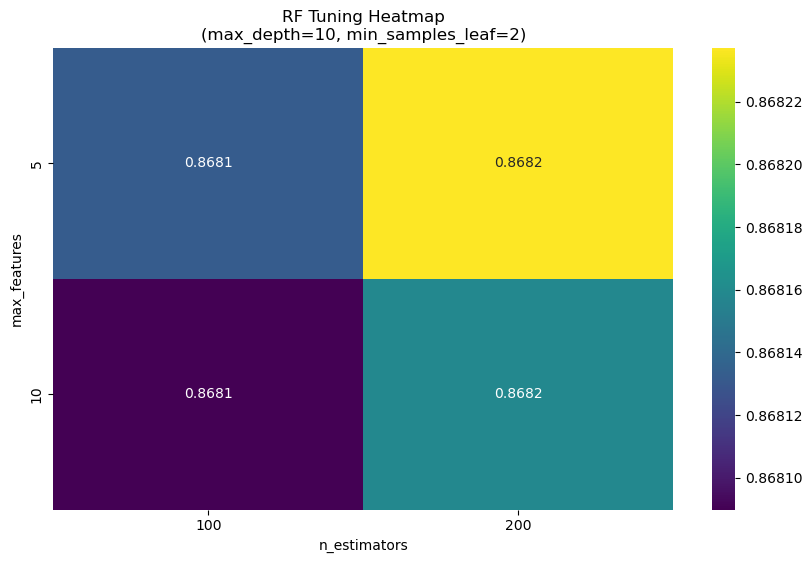

In [20]:
results = pd.DataFrame(tuning_res_rf.cv_results_)

# Get best regularization parameters
best_depth = tuning_res_rf.best_params_["max_depth"]
best_leaf = tuning_res_rf.best_params_["min_samples_leaf"]

filtered_results = results[
    (results["param_max_depth"] == best_depth) &
    (results["param_min_samples_leaf"] == best_leaf)
]

pivot_table = filtered_results.pivot(
    index="param_max_features",
    columns="param_n_estimators",
    values="mean_test_score"
)

plt.figure(figsize=(10,6))

# A heatmap is generated to visualize model performance across key hyperparameter combinations (n_estimators, max_features)
sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".4f",
    cmap="viridis"
)

plt.xlabel("n_estimators")
plt.ylabel("max_features")
plt.title(
    f"RF Tuning Heatmap\n(max_depth={best_depth}, min_samples_leaf={best_leaf})"
)

plt.show()

In [21]:
# Best parameter set for RF model after tuning

print("Best RF Parameters:")
print(tuning_res_rf.best_params_)

Best_RF = tuning_res_rf.best_estimator_

Best RF Parameters:
{'max_depth': 10, 'max_features': 5, 'min_samples_leaf': 2, 'n_estimators': 200}


In [22]:
# Test set evaluation
y_pred_rf = Best_RF.predict(X_test)
y_pred_rf_proba = Best_RF.predict_proba(X_test)[:, 1]
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_pred_rf_proba)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))


Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.80      0.82     14660
           1       0.76      0.81      0.78     11281

    accuracy                           0.81     25941
   macro avg       0.80      0.81      0.80     25941
weighted avg       0.81      0.81      0.81     25941



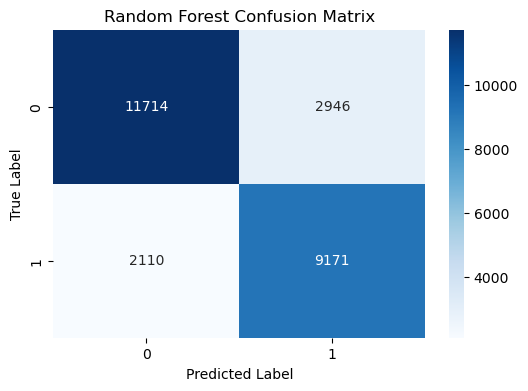

In [23]:
# A confusion matrix is used to analyze prediction outcomes.

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

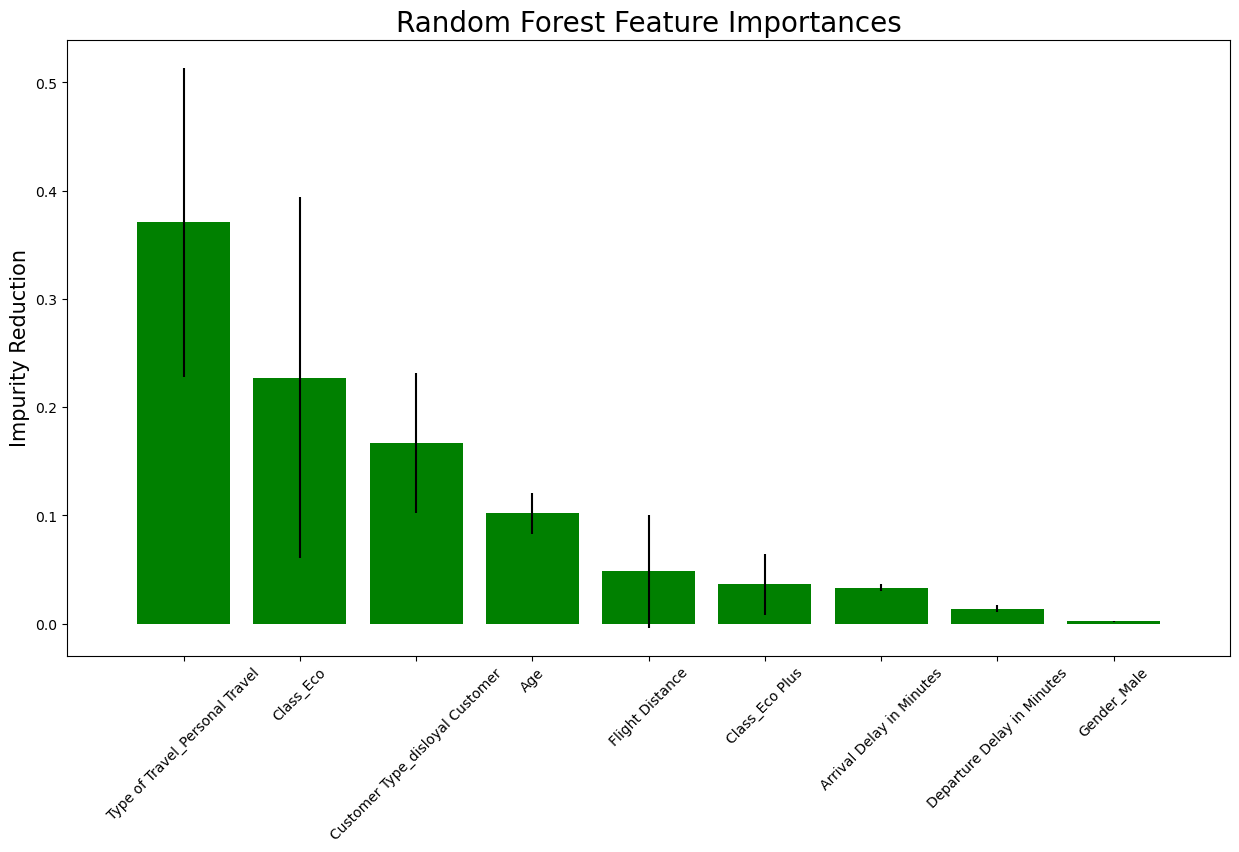

In [24]:
# Extracts and visualizes feature importance scores with std across trees for top predictors.

feature_names = X.columns

importances = Best_RF.feature_importances_

std = np.std(
    [tree.feature_importances_ for tree in Best_RF.estimators_],
    axis=0
)

indices = np.argsort(importances)[::-1]

num_feat = min(10, len(importances))

plt.figure(figsize=(15,8))
plt.title("Random Forest Feature Importances", fontsize=20)

plt.bar(
    range(num_feat),
    importances[indices][:num_feat],
    color="g",
    yerr=std[indices][:num_feat],
    align="center"
)

plt.xticks(
    range(num_feat),
    feature_names[indices][:num_feat],
    rotation=45
)

plt.xlim([-1, num_feat])
plt.ylabel("Impurity Reduction", fontsize=15)

plt.show()

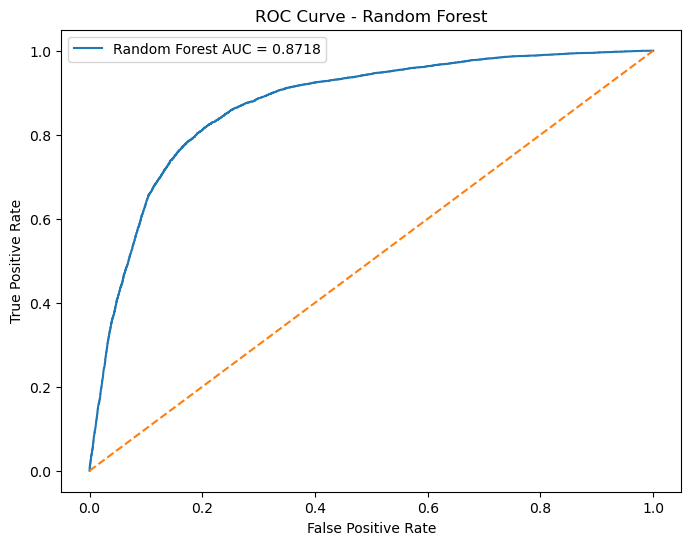

In [25]:
#The ROC curve visualizes classification performance across thresholds.

fpr, tpr, _ = roc_curve(y_test, y_pred_rf_proba)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest AUC = {rf_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()

plt.show()

Training and testing AUC scores are compared:
Detect overfitting
Measure generalization
Evaluate train-test performance gap

In [26]:
# Training and testing AUC scores are compared in order to detect overfitting

# Train AUC
y_train_rf_proba = Best_RF.predict_proba(X_train)[:, 1]
train_auc_rf = roc_auc_score(y_train, y_train_rf_proba)

# Test AUC
test_auc_rf = rf_auc

print(f"Random Forest Train AUC: {train_auc_rf:.4f}")
print(f"Random Forest Test AUC:  {test_auc_rf:.4f}")

Random Forest Train AUC: 0.8835
Random Forest Test AUC:  0.8718


# Gradient Boosted Trees

In [27]:
# Tuning GBT hyperparameters

param_dist_gbt = {
    "n_estimators":  randint(100, 400),
    "learning_rate": uniform(0.01, 0.25),
    "max_depth":     randint(2, 6),
    "subsample":     uniform(0.6, 0.4),
}

tuning_res_gbc = RandomizedSearchCV(
    GBC(random_state=42),
    param_distributions=param_dist_gbt,
    n_iter=30,
    scoring="roc_auc",
    cv=3,
    n_jobs=1,
    random_state=42,
    verbose=2,
)
tuning_res_gbc.fit(X_train, y_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV] END learning_rate=0.10363502971184062, max_depth=2, n_estimators=370, subsample=0.892797576724562; total time=  10.0s
[CV] END learning_rate=0.10363502971184062, max_depth=2, n_estimators=370, subsample=0.892797576724562; total time=  10.4s
[CV] END learning_rate=0.10363502971184062, max_depth=2, n_estimators=370, subsample=0.892797576724562; total time=  10.1s
[CV] END learning_rate=0.15966462104925916, max_depth=4, n_estimators=221, subsample=0.662397808134481; total time=   9.1s
[CV] END learning_rate=0.15966462104925916, max_depth=4, n_estimators=221, subsample=0.662397808134481; total time=   8.8s
[CV] END learning_rate=0.15966462104925916, max_depth=4, n_estimators=221, subsample=0.662397808134481; total time=   8.7s
[CV] END learning_rate=0.024520903042049867, max_depth=5, n_estimators=199, subsample=0.6571467271687763; total time=   9.6s
[CV] END learning_rate=0.024520903042049867, max_depth=5, n_estimators=199, 

RandomizedSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=42),
                   n_iter=30, n_jobs=1,
                   param_distributions={'learning_rate': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x00000229032C3E00>,
                                        'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002290E3B3390>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x00000229032C3CB0>,
                                        'subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000002290E3B3890>},
                   random_state=42, scoring='roc_auc', verbose=2)

In [28]:
print("Best hyperparameters (GBT):")
print(tuning_res_gbc.best_params_)

Best_GBT = tuning_res_gbc.best_estimator_

Best hyperparameters (GBT):
{'learning_rate': np.float64(0.02166641580340386), 'max_depth': 5, 'n_estimators': 370, 'subsample': np.float64(0.7824279936868144)}


In [29]:
# Test set evaluation
y_pred_gbt = Best_GBT.predict(X_test)
y_pred_gbt_proba = Best_GBT.predict_proba(X_test)[:, 1]

gbt_auc = roc_auc_score(y_test, y_pred_gbt_proba)

print(f"Gradient Boosted Trees Test AUC       : {gbt_auc:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_gbt))

Gradient Boosted Trees Test AUC       : 0.8719

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.82      0.83     14660
           1       0.77      0.80      0.78     11281

    accuracy                           0.81     25941
   macro avg       0.80      0.81      0.80     25941
weighted avg       0.81      0.81      0.81     25941



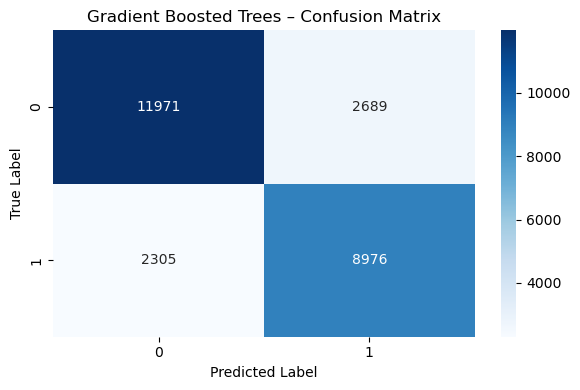

In [30]:
#Confusion Matrix

cm_gbt = confusion_matrix(y_test, y_pred_gbt)
 
plt.figure(figsize=(6, 4))
sns.heatmap(cm_gbt, annot=True, fmt="d", cmap="Blues")
plt.title("Gradient Boosted Trees – Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

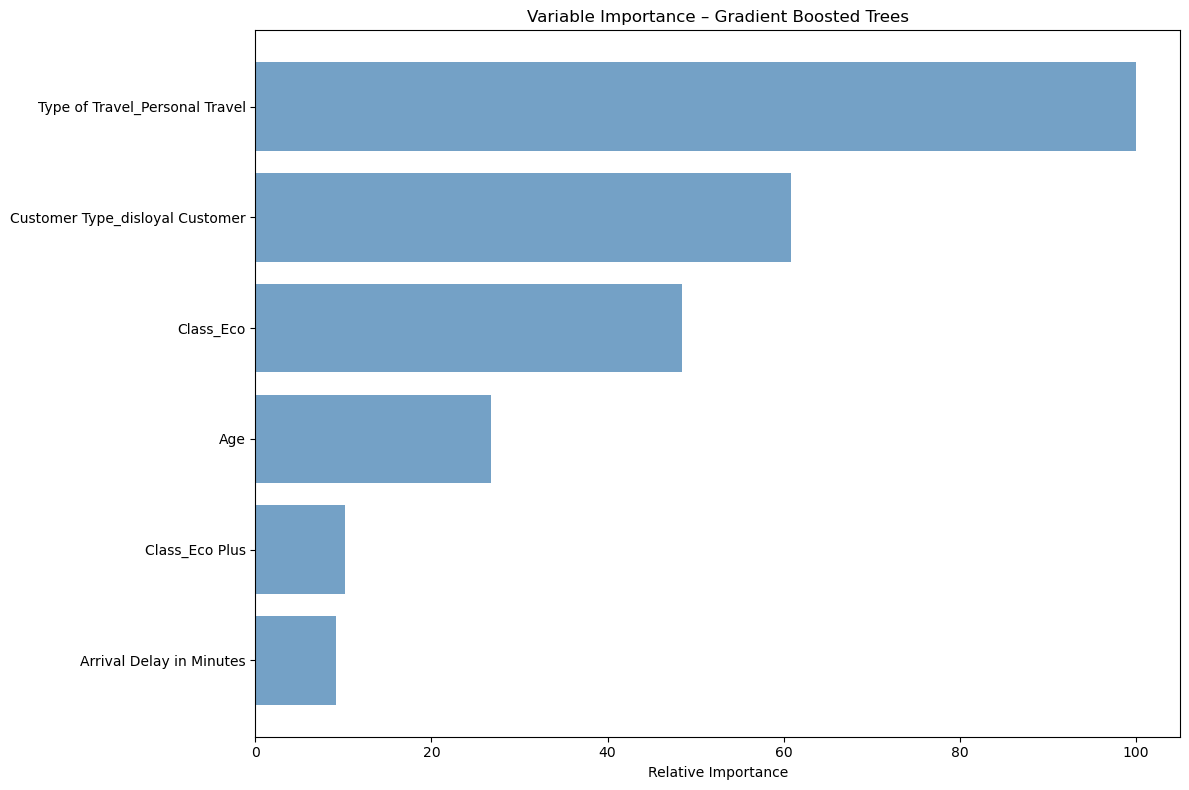

In [31]:
#Feature importance for GBT

feature_importance = Best_GBT.feature_importances_
 
feature_importance = 100.0 * (feature_importance / feature_importance.max())
 
sorted_idx = np.argsort(feature_importance)
pos = np.arange(sorted_idx.shape[0]) + 0.5
num_feat = 6
 
plt.figure(figsize=(12, 8))
plt.barh(
    pos[-num_feat:],
    feature_importance[sorted_idx][-num_feat:],
    align="center",
    alpha=0.75,
    color="steelblue",
)
plt.yticks(pos[-num_feat:], X_train.columns[sorted_idx][-num_feat:])
plt.xlabel("Relative Importance")
plt.title("Variable Importance – Gradient Boosted Trees")
plt.tight_layout()
plt.show()

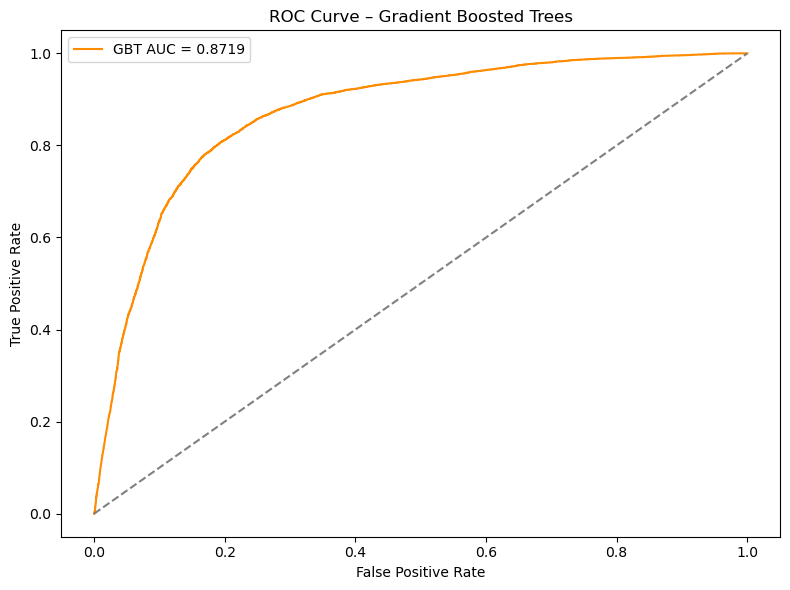

In [32]:
#ROC Curve

fpr_gbt, tpr_gbt, _ = roc_curve(y_test, y_pred_gbt_proba)
 
plt.figure(figsize=(8, 6))
plt.plot(fpr_gbt, tpr_gbt, label=f"GBT AUC = {gbt_auc:.4f}", color="darkorange")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Gradient Boosted Trees")
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
y_train_gbt_proba = Best_GBT.predict_proba(X_train)[:, 1]
train_auc_gbt     = roc_auc_score(y_train, y_train_gbt_proba)

# Train set AUC
print(f"Gradient Boosted Trees Train AUC : {train_auc_gbt:.4f}")

# Test set AUC
print(f"Gradient Boosted Trees Test AUC  : {gbt_auc:.4f}")

Gradient Boosted Trees Train AUC : 0.8756
Gradient Boosted Trees Test AUC  : 0.8719


# Comparing results of the 3 models

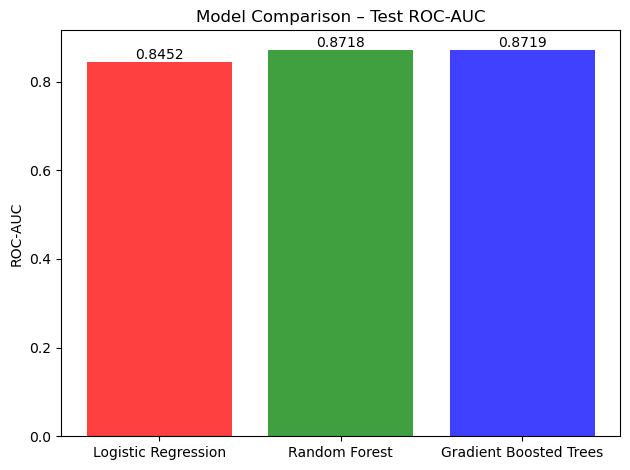

In [34]:
models   = [best_lr_model, Best_RF, Best_GBT]
auc_test = [roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for m in models]

fig = plt.bar(
    ["Logistic Regression", "Random Forest", "Gradient Boosted Trees"],
    auc_test,
    color=["red", "green", "blue"],
    alpha=0.75,
)
plt.bar_label(fig, fmt="%.4f")
plt.ylabel("ROC-AUC")
plt.title("Model Comparison – Test ROC-AUC")
plt.tight_layout()
plt.show()

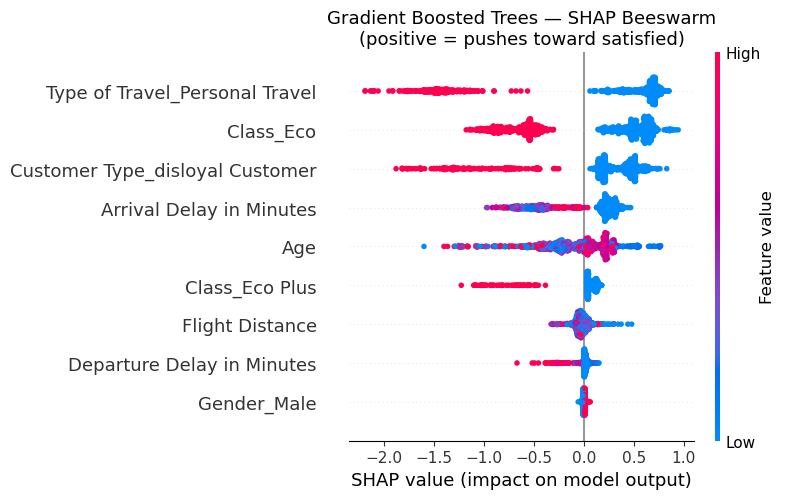

In [42]:
# !pip install shap

import shap

sample_size = 1000
X_sample = X_test.sample(sample_size, random_state=42)

explainer_gbt   = shap.TreeExplainer(Best_GBT)
explanation_gbt = explainer_gbt(X_sample)

shap.plots.beeswarm(explanation_gbt, max_display=10, show=False)
plt.title('Gradient Boosted Trees — SHAP Beeswarm\n(positive = pushes toward satisfied)', fontsize=13)
plt.tight_layout()
plt.show()

After conducting hyperparameter tuning using GridSearchCV/RandomizedSearchCV, we compared the performance of three models:
Logistic Regression, Random Forest, and Gradient Boosted Trees.

# Model Selection

The Gradient Boosted Trees model was selected as the final model. While Random Forest achieved a slightly higher training score,
GBT demonstrated the best balance between high predictive power and stability (minimal difference between Train and Test AUC).
This suggests that GBT is the most robust model and less prone to overfitting, making it the most reliable for predicting satisfaction on new, unseen data.

# Feature Importance

The feature importance analysis for both Random Forest and Gradient Boosted Trees identifies "Type of Travel_Personal Travel" as the primary predictor of satisfaction, followed by "Customer Type_disloyal Customer" and "Class_Eco." Beyond these top drivers, the models show that demographic and situational factors such as Age and Flight Distance also play a role in determining passenger sentiment. Additionally, while service-related variables like Arrival Delay in Minutes and Class_Eco Plus contribute to the final classification, their relative impact is notably lower than the travel category and passenger loyalty status.

# Challenges

The primary challenge encountered during the project was the significant size of the dataset, which contained over 120,000 records. This large volume of data made the modeling process and hyperparameter tuning extremely computationally intensive. To ensure the analysis could be completed within a reasonable timeframe, it was necessary to optimize the search process by limiting the number of iterations in the RandomizedSearchCV and carefully selecting the range of parameters for the ensemble models.

Another significant challenge was identifying and addressing data leakage. Several original features were directly derived from passenger satisfaction ratings, creating an artificial correlation with the target variable. To ensure the model's integrity and predictive power on real-world data, these redundant features had to be removed during the preprocessing stage.